In [1]:
from D1D2_metrics import D1D2

In [2]:
true_drift = [1000,2000,2500]
detected = [900,1100,1500,1900]

In [3]:


TPR = D1D2.tpr(true_drift,detected,200)
FDR = D1D2.fdr(true_drift,detected,200)
D1 = D1D2.D1(true_drift,detected)
# if(len(detected)==0):
#     detected = [10000]
# D2 = D1D2.D2(True_drift,detected)
try:
    D2 = D1D2.D2(true_drift,detected)
except:
     D2 = None

b_mean = D1D2.b_mean(true_drift,detected, 200)
g_mean = D1D2.g_mean(true_drift,detected, 200)

In [4]:
print(f'Real drift points: {true_drift}')
print(f'Detected drift points: {detected}')
print(f'Distance based metrics')
print(f'\tD1: {D1}')
print(f'\tD2: {D2}')
print(f'Classification based metrics')
print(f'\tTPR: {TPR}')
print(f'\tFDR: {FDR}')
print(f'\tBalanced mean: {b_mean}')
print(f'\tGeometric mean: {g_mean}')

Real drift points: [1000, 2000, 2500]
Detected drift points: [900, 1100, 1500, 1900]
Distance based metrics
	D1: 200.0
	D2: 266.6666666666667
Classification based metrics
	TPR: 0.6666666666666666
	FDR: 0.5
	Balanced mean: 0.5833333333333333
	Geometric mean: 0.5773502691896257


## Critical Difference Diagram for D1/D2 comparison

Rows represent datasets, streams, or repeated experimental scenarios. Columns represent algorithms.
For D1 and D2 metrics, lower values are better, so `lower_is_better=True`.


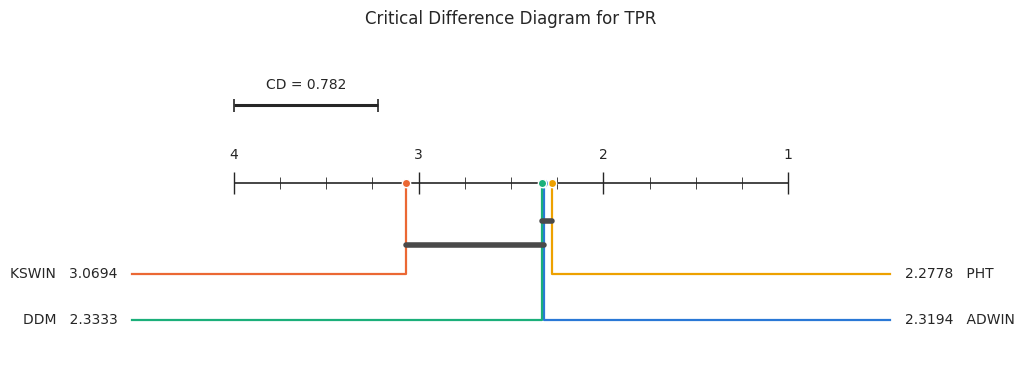

In [5]:
import pandas as pd
from D1D2_metrics import StatisticalComparison

# Example D1 results: rows = scenarios, columns = algorithms
d1_results = pd.DataFrame({
    "ADWIN": [0.5, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.5, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0],
    "KSWIN": [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0],
    "DDM": [0.5, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0],
    "PHT": [0.5, 1.0, 1.0, 0.5, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.5, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0],

})

cd_result = StatisticalComparison.critical_difference_diagram(
    d1_results,
    lower_is_better=False,
    alpha=0.05,
    title="Critical Difference Diagram for TPR",
    save_path="../data/graphs/cd_diagram_TPR.png",
)


In [9]:
print(f"Friedman p-value: {cd_result["friedman_pvalue"]:.4f}")
print("Average ranks:")
display(cd_result["average_ranks"])
print("Nemenyi pairwise p-values:")
display(cd_result["nemenyi_pvalues"])


Friedman p-value: 0.0000
Average ranks:


KSWIN    1.930556
DDM      2.666667
ADWIN    2.680556
PHT      2.722222
dtype: float64

Nemenyi pairwise p-values:


,ADWIN,KSWIN,DDM,PHT
ADWIN,1.000000,0.065541,0.999966,0.999084
KSWIN,0.065541,1.000000,0.073497,0.045821
DDM,0.999966,0.073497,1.000000,0.997841
PHT,0.999084,0.045821,0.997841,1.000000
